Make sure that files can be properly loaded from our GDrive folder.

See `README.md` in Drive for information on the results dataset.

# Load necessary packages

In [1]:
import json
import requests

import pandas as pd

import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

**Load results dataset**

In [2]:
with open("data/results/results_all.json") as f:
    data = json.load(f)

results_list = []
for entry in data:
  smelly_requirements = entry.get('smelly_requirements', [])

  requirements_df = pd.json_normalize(entry, 'requirements', ['id', 'game', 'experiment', 'timestamp', 'run', 'model'])

  # Add the 'smelly' column by checking if 'requirement_id' is in 'smelly_requirements'
  requirements_df['smelly'] = requirements_df['requirement_id'].isin(smelly_requirements)

  results_list.append(requirements_df)

# Concatenate all DataFrames at once
results = pd.concat(results_list, ignore_index=True)

results

,requirement_id,implemented,lines_of_code,id,game,experiment,timestamp,run,model,smelly
0,1,True,"[3, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24...",dice_game/no_smells_01/2026-10-12_042255/01,dice_game,no_smells_01,2026-10-12_042255,1,gpt-4o-2024-08-06,False
1,2,True,[21],dice_game/no_smells_01/2026-10-12_042255/01,dice_game,no_smells_01,2026-10-12_042255,1,gpt-4o-2024-08-06,False
2,3,True,"[49, 50, 51, 52, 53, 54, 55, 56, 57, 58, 59, 6...",dice_game/no_smells_01/2026-10-12_042255/01,dice_game,no_smells_01,2026-10-12_042255,1,gpt-4o-2024-08-06,False
3,4,True,[51],dice_game/no_smells_01/2026-10-12_042255/01,dice_game,no_smells_01,2026-10-12_042255,1,gpt-4o-2024-08-06,False
4,5,True,[60],dice_game/no_smells_01/2026-10-12_042255/01,dice_game,no_smells_01,2026-10-12_042255,1,gpt-4o-2024-08-06,False
...,...,...,...,...,...,...,...,...,...,...
10335,16,True,"[112, 110, 111]",pong/random_20/2026-10-12_042255/05,pong,random_20,2026-10-12_042255,5,gpt-4o-2024-08-06,True
10336,17,True,"[114, 115, 116, 117, 118, 119, 120, 121, 122, ...",pong/random_20/2026-10-12_042255/05,pong,random_20,2026-10-12_042255,5,gpt-4o-2024-08-06,True
10337,18,True,"[105, 93, 97]",pong/random_20/2026-10-12_042255/05,pong,random_20,2026-10-12_042255,5,gpt-4o-2024-08-06,True
10338,19,True,"[83, 76]",pong/random_20/2026-10-12_042255/05,pong,random_20,2026-10-12_042255,5,gpt-4o-2024-08-06,True


**Load ground truth dataset**

In [3]:
ground_truth = pd.read_csv("ground_truth.csv")
ground_truth

,game,requirement_id,smell_type,smell_category,implemented,lines,smelly_traceable
0,dice_game,1,NaN,NaN,yes,30,NaN
1,dice_game,2,NaN,NaN,yes,21,NaN
2,dice_game,3,NaN,NaN,yes,"42, 43, 45, 46, 47, 48, 49, 50, 51, 52, 53, 54...",NaN
3,dice_game,4,NaN,NaN,yes,"51, 56",NaN
4,dice_game,5,NaN,NaN,yes,60,NaN
...,...,...,...,...,...,...,...
89,pong,16,optional_parts,lexical,yes,"110, 111",yes
90,pong,17,subjective_language,lexical,yes,"114, 115, 116, 117, 118, 119, 120, 121, 122, 123",yes
91,pong,18,optional_parts,lexical,yes,"105, 107, 108, 110, 111, 117, 122",yes
92,pong,19,vague_pronouns,syntactic,yes,"76, 83",yes


# Preprocessing

**Convert the 'implemented' and 'smelly_traceable' columns in `ground_truth` and `results` from "yes"/"no" to True/False to make it consistent**

In [4]:
# Convert the 'implemented' column in results to True/False to make it consistent
results['implemented'] = results['implemented'].map({"yes": True, "no": False, True: True, False: False})

# Convert the 'implemented' column in ground_truth from "yes"/"no" to True/False to make it consistent with the results df
ground_truth['implemented'] = ground_truth['implemented'].map({"yes": True, "no": False})

# Convert the 'smelly_traceable' column in ground_truth from "yes"/"no" to True/False to make it consistent with the results df
ground_truth['smelly_traceable'] = ground_truth['smelly_traceable'].map({"yes": True, "no": False})

ground_truth

,game,requirement_id,smell_type,smell_category,implemented,lines,smelly_traceable
0,dice_game,1,NaN,NaN,True,30,NaN
1,dice_game,2,NaN,NaN,True,21,NaN
2,dice_game,3,NaN,NaN,True,"42, 43, 45, 46, 47, 48, 49, 50, 51, 52, 53, 54...",NaN
3,dice_game,4,NaN,NaN,True,"51, 56",NaN
4,dice_game,5,NaN,NaN,True,60,NaN
...,...,...,...,...,...,...,...
89,pong,16,optional_parts,lexical,True,"110, 111",True
90,pong,17,subjective_language,lexical,True,"114, 115, 116, 117, 118, 119, 120, 121, 122, 123",True
91,pong,18,optional_parts,lexical,True,"105, 107, 108, 110, 111, 117, 122",True
92,pong,19,vague_pronouns,syntactic,True,"76, 83",True


**Merge results and ground truth**

In [5]:
# Merge results and ground truth on game and requirements id
results_truth_merged = pd.merge(results, ground_truth, how='inner', on=['requirement_id', 'game'], suffixes=('_pred', '_actual'))
results_truth_merged

,requirement_id,implemented_pred,lines_of_code,id,game,experiment,timestamp,run,model,smelly,smell_type,smell_category,implemented_actual,lines,smelly_traceable
0,1,True,"[3, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24...",dice_game/no_smells_01/2026-10-12_042255/01,dice_game,no_smells_01,2026-10-12_042255,1,gpt-4o-2024-08-06,False,NaN,NaN,True,30,NaN
1,2,True,[21],dice_game/no_smells_01/2026-10-12_042255/01,dice_game,no_smells_01,2026-10-12_042255,1,gpt-4o-2024-08-06,False,NaN,NaN,True,21,NaN
2,3,True,"[49, 50, 51, 52, 53, 54, 55, 56, 57, 58, 59, 6...",dice_game/no_smells_01/2026-10-12_042255/01,dice_game,no_smells_01,2026-10-12_042255,1,gpt-4o-2024-08-06,False,NaN,NaN,True,"42, 43, 45, 46, 47, 48, 49, 50, 51, 52, 53, 54...",NaN
3,4,True,[51],dice_game/no_smells_01/2026-10-12_042255/01,dice_game,no_smells_01,2026-10-12_042255,1,gpt-4o-2024-08-06,False,NaN,NaN,True,"51, 56",NaN
4,5,True,[60],dice_game/no_smells_01/2026-10-12_042255/01,dice_game,no_smells_01,2026-10-12_042255,1,gpt-4o-2024-08-06,False,NaN,NaN,True,60,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
10335,16,True,"[112, 110, 111]",pong/random_20/2026-10-12_042255/05,pong,random_20,2026-10-12_042255,5,gpt-4o-2024-08-06,True,optional_parts,lexical,True,"110, 111",True
10336,17,True,"[114, 115, 116, 117, 118, 119, 120, 121, 122, ...",pong/random_20/2026-10-12_042255/05,pong,random_20,2026-10-12_042255,5,gpt-4o-2024-08-06,True,subjective_language,lexical,True,"114, 115, 116, 117, 118, 119, 120, 121, 122, 123",True
10337,18,True,"[105, 93, 97]",pong/random_20/2026-10-12_042255/05,pong,random_20,2026-10-12_042255,5,gpt-4o-2024-08-06,True,optional_parts,lexical,True,"105, 107, 108, 110, 111, 117, 122",True
10338,19,True,"[83, 76]",pong/random_20/2026-10-12_042255/05,pong,random_20,2026-10-12_042255,5,gpt-4o-2024-08-06,True,vague_pronouns,syntactic,True,"76, 83",True


**Rename loc columns with more meaningful names**

In [6]:
results_truth_merged = results_truth_merged.rename(columns={"lines_of_code": "loc_predicted", "lines": "loc_actual"})
results_truth_merged


,requirement_id,implemented_pred,loc_predicted,id,game,experiment,timestamp,run,model,smelly,smell_type,smell_category,implemented_actual,loc_actual,smelly_traceable
0,1,True,"[3, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24...",dice_game/no_smells_01/2026-10-12_042255/01,dice_game,no_smells_01,2026-10-12_042255,1,gpt-4o-2024-08-06,False,NaN,NaN,True,30,NaN
1,2,True,[21],dice_game/no_smells_01/2026-10-12_042255/01,dice_game,no_smells_01,2026-10-12_042255,1,gpt-4o-2024-08-06,False,NaN,NaN,True,21,NaN
2,3,True,"[49, 50, 51, 52, 53, 54, 55, 56, 57, 58, 59, 6...",dice_game/no_smells_01/2026-10-12_042255/01,dice_game,no_smells_01,2026-10-12_042255,1,gpt-4o-2024-08-06,False,NaN,NaN,True,"42, 43, 45, 46, 47, 48, 49, 50, 51, 52, 53, 54...",NaN
3,4,True,[51],dice_game/no_smells_01/2026-10-12_042255/01,dice_game,no_smells_01,2026-10-12_042255,1,gpt-4o-2024-08-06,False,NaN,NaN,True,"51, 56",NaN
4,5,True,[60],dice_game/no_smells_01/2026-10-12_042255/01,dice_game,no_smells_01,2026-10-12_042255,1,gpt-4o-2024-08-06,False,NaN,NaN,True,60,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
10335,16,True,"[112, 110, 111]",pong/random_20/2026-10-12_042255/05,pong,random_20,2026-10-12_042255,5,gpt-4o-2024-08-06,True,optional_parts,lexical,True,"110, 111",True
10336,17,True,"[114, 115, 116, 117, 118, 119, 120, 121, 122, ...",pong/random_20/2026-10-12_042255/05,pong,random_20,2026-10-12_042255,5,gpt-4o-2024-08-06,True,subjective_language,lexical,True,"114, 115, 116, 117, 118, 119, 120, 121, 122, 123",True
10337,18,True,"[105, 93, 97]",pong/random_20/2026-10-12_042255/05,pong,random_20,2026-10-12_042255,5,gpt-4o-2024-08-06,True,optional_parts,lexical,True,"105, 107, 108, 110, 111, 117, 122",True
10338,19,True,"[83, 76]",pong/random_20/2026-10-12_042255/05,pong,random_20,2026-10-12_042255,5,gpt-4o-2024-08-06,True,vague_pronouns,syntactic,True,"76, 83",True


**Align the datatypes of `loc_actual` and `loc_predicted`**

In [7]:
# prompt: In results_truth_merged, column loc_actual contains either a single number or a series of strings. Convert the values to a list of numbers and replace the values in the df.

def to_int_list(x):
  if isinstance(x, str):
    return [int(i) for i in x.split(',')]
  elif isinstance(x, int):
    return [x]
  else:
    return []

results_truth_merged['loc_actual'] = results_truth_merged['loc_actual'].apply(to_int_list)
results_truth_merged

,requirement_id,implemented_pred,loc_predicted,id,game,experiment,timestamp,run,model,smelly,smell_type,smell_category,implemented_actual,loc_actual,smelly_traceable
0,1,True,"[3, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24...",dice_game/no_smells_01/2026-10-12_042255/01,dice_game,no_smells_01,2026-10-12_042255,1,gpt-4o-2024-08-06,False,NaN,NaN,True,[30],NaN
1,2,True,[21],dice_game/no_smells_01/2026-10-12_042255/01,dice_game,no_smells_01,2026-10-12_042255,1,gpt-4o-2024-08-06,False,NaN,NaN,True,[21],NaN
2,3,True,"[49, 50, 51, 52, 53, 54, 55, 56, 57, 58, 59, 6...",dice_game/no_smells_01/2026-10-12_042255/01,dice_game,no_smells_01,2026-10-12_042255,1,gpt-4o-2024-08-06,False,NaN,NaN,True,"[42, 43, 45, 46, 47, 48, 49, 50, 51, 52, 53, 5...",NaN
3,4,True,[51],dice_game/no_smells_01/2026-10-12_042255/01,dice_game,no_smells_01,2026-10-12_042255,1,gpt-4o-2024-08-06,False,NaN,NaN,True,"[51, 56]",NaN
4,5,True,[60],dice_game/no_smells_01/2026-10-12_042255/01,dice_game,no_smells_01,2026-10-12_042255,1,gpt-4o-2024-08-06,False,NaN,NaN,True,[60],NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
10335,16,True,"[112, 110, 111]",pong/random_20/2026-10-12_042255/05,pong,random_20,2026-10-12_042255,5,gpt-4o-2024-08-06,True,optional_parts,lexical,True,"[110, 111]",True
10336,17,True,"[114, 115, 116, 117, 118, 119, 120, 121, 122, ...",pong/random_20/2026-10-12_042255/05,pong,random_20,2026-10-12_042255,5,gpt-4o-2024-08-06,True,subjective_language,lexical,True,"[114, 115, 116, 117, 118, 119, 120, 121, 122, ...",True
10337,18,True,"[105, 93, 97]",pong/random_20/2026-10-12_042255/05,pong,random_20,2026-10-12_042255,5,gpt-4o-2024-08-06,True,optional_parts,lexical,True,"[105, 107, 108, 110, 111, 117, 122]",True
10338,19,True,"[83, 76]",pong/random_20/2026-10-12_042255/05,pong,random_20,2026-10-12_042255,5,gpt-4o-2024-08-06,True,vague_pronouns,syntactic,True,"[76, 83]",True


**Do a majority vote over the five runs and replace the 5 runs with the most frequent value. For LOC tracing, do the majority vote per line.**

In [8]:
from collections import Counter

# Drop the specified columns
results_truth_merged_dropped = results_truth_merged.drop(columns=['id', 'timestamp'])

# Optimized custom aggregation function using mode()
def most_common_or_nan(series):
    if series.isnull().all():
        return np.nan
    return series.mode()[0]  # mode() returns a Series; take the first mode

# Optimized custom function for 'loc_actual' and 'loc_predicted'
def most_common_list_values(series, threshold=2):
    if series.isnull().all():
        return np.nan
    # Flatten the list of lists and count occurrences
    counter = Counter(item for sublist in series.dropna() for item in sublist)
    # Select items that occur more than the threshold
    common_items = [item for item, count in counter.items() if count > threshold]
    return common_items if common_items else np.nan

# Group the DataFrame and aggregate by the most common value or custom logic
results_truth_merged_grouped = results_truth_merged_dropped.groupby(
    ['model', 'requirement_id', 'game', 'experiment'], as_index=False
).agg(
    {
        **{col: most_common_or_nan for col in results_truth_merged_dropped.columns if col not in ['loc_actual', 'loc_predicted', 'run']},
        'loc_actual': lambda x: most_common_list_values(x, threshold=2),
        'loc_predicted': lambda x: most_common_list_values(x, threshold=2)
    }
)

# Drop the superfluous 'run' column if it exists in the resulting DataFrame
results_truth_merged_grouped = results_truth_merged_grouped.drop(columns=['run'], errors='ignore')

# Display the resulting DataFrame
results_truth_merged_grouped



,requirement_id,implemented_pred,game,experiment,model,smelly,smell_type,smell_category,implemented_actual,smelly_traceable,loc_actual,loc_predicted
0,1,True,arkanoid,all_smells_01,gpt-4o-2024-08-06,False,NaN,NaN,True,NaN,"[6, 116]","[6, 138, 108, 115, 116]"
1,1,True,arkanoid,no_smells_01,gpt-4o-2024-08-06,False,NaN,NaN,True,NaN,"[6, 116]","[116, 6]"
2,1,True,arkanoid,random_01,gpt-4o-2024-08-06,False,NaN,NaN,True,NaN,"[6, 116]","[116, 6, 14]"
3,1,True,arkanoid,random_02,gpt-4o-2024-08-06,False,NaN,NaN,True,NaN,"[6, 116]","[6, 138, 108, 115, 116, 109]"
4,1,True,arkanoid,random_03,gpt-4o-2024-08-06,False,NaN,NaN,True,NaN,"[6, 116]","[138, 116, 6]"
...,...,...,...,...,...,...,...,...,...,...,...,...
2063,25,False,dice_game,random_16,gpt-4o-2024-08-06,False,subjective_language,lexical,False,False,NaN,NaN
2064,25,False,dice_game,random_17,gpt-4o-2024-08-06,True,subjective_language,lexical,False,False,NaN,NaN
2065,25,False,dice_game,random_18,gpt-4o-2024-08-06,False,subjective_language,lexical,False,False,NaN,NaN
2066,25,False,dice_game,random_19,gpt-4o-2024-08-06,True,subjective_language,lexical,False,False,NaN,NaN


**Add the actual percentage of smelly requirements over all requirements**

In [9]:
# prompt: Group results_truth_merged_grouped by model, game, experiment. Add a column "percentage_smelly" that contains the percentage of rows with smelly=True.

# Group by model, game, and experiment
grouped_results = results_truth_merged_grouped.groupby(['model', 'game', 'experiment'])

# Calculate the percentage of smelly requirements for each group
percentage_smelly = grouped_results['smelly'].mean() * 100

# Add the percentage_smelly column to the original DataFrame
results_truth_merged_grouped['percentage_smelly'] = results_truth_merged_grouped.apply(lambda row: percentage_smelly[(row['model'], row['game'], row['experiment'])], axis=1)

results_truth_merged_grouped[(results_truth_merged_grouped['game']=='snake')&(results_truth_merged_grouped['model']=='gpt-4o-2024-08-06')&(results_truth_merged_grouped['experiment'].str.startswith('all'))]


,requirement_id,implemented_pred,game,experiment,model,smelly,smell_type,smell_category,implemented_actual,smelly_traceable,loc_actual,loc_predicted,percentage_smelly
88,1,True,snake,all_smells_01,gpt-4o-2024-08-06,False,NaN,NaN,True,NaN,"[88, 89, 90, 91, 92, 97, 129, 130, 58, 59, 60,...","[96, 97, 129, 130, 131, 88, 89, 90, 91, 92, 93...",78.571429
198,2,True,snake,all_smells_01,gpt-4o-2024-08-06,False,NaN,NaN,True,NaN,"[58, 59, 60, 61, 120, 121, 122]","[122, 123, 120, 121, 58, 59, 60, 61, 62]",78.571429
308,3,True,snake,all_smells_01,gpt-4o-2024-08-06,False,NaN,NaN,True,NaN,"[58, 59, 60, 61, 120, 121, 122]","[40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 5...",78.571429
418,4,False,snake,all_smells_01,gpt-4o-2024-08-06,True,negative,syntactic,False,False,NaN,NaN,78.571429
528,5,True,snake,all_smells_01,gpt-4o-2024-08-06,True,passive_voice,syntactic,True,True,"[64, 65, 67, 68, 70, 71, 75, 125, 126]","[64, 65, 66, 67, 68, 69, 70, 71, 72, 73, 74, 7...",78.571429
638,6,True,snake,all_smells_01,gpt-4o-2024-08-06,True,subjective_language,lexical,False,False,"[6, 81, 82, 83, 84, 85]","[25, 30, 31, 32, 33, 34, 35, 36, 37, 38, 78, 7...",78.571429
748,7,True,snake,all_smells_01,gpt-4o-2024-08-06,True,vague_pronouns,syntactic,True,True,"[30, 31, 33, 34, 35, 36, 37, 78, 79, 81, 82, 8...","[32, 33, 34, 35, 36, 37, 38, 78, 79, 80, 81, 8...",78.571429
858,8,True,snake,all_smells_01,gpt-4o-2024-08-06,True,weak_verbs,lexical,True,False,"[8, 9, 10, 11, 12, 43, 44, 45, 46, 47, 48, 49,...","[108, 109, 110, 111, 112, 113, 114, 115, 116, ...",78.571429
968,9,True,snake,all_smells_01,gpt-4o-2024-08-06,True,ambiguities,semantic,True,True,[122],"[120, 121, 122, 123]",78.571429
1078,10,False,snake,all_smells_01,gpt-4o-2024-08-06,True,numerical_discrepancies,semantic,False,False,NaN,NaN,78.571429


# RQ1: General Tracing Performance

Binary tracing accuracy (BTA) and the LOC tracing precision and recall achieved in the runs with 0% smelly requirements.  

In [10]:
# Select only the experiments with no smelly requirements
results_no_smells=results_truth_merged_grouped[(results_truth_merged_grouped["experiment"] == "no_smells_01")]
results_no_smells

,requirement_id,implemented_pred,game,experiment,model,smelly,smell_type,smell_category,implemented_actual,smelly_traceable,loc_actual,loc_predicted,percentage_smelly
1,1,True,arkanoid,no_smells_01,gpt-4o-2024-08-06,False,NaN,NaN,True,NaN,"[6, 116]","[116, 6]",0.0
23,1,True,dice_game,no_smells_01,gpt-4o-2024-08-06,False,NaN,NaN,True,NaN,[30],"[3, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24...",0.0
45,1,True,pong,no_smells_01,gpt-4o-2024-08-06,False,NaN,NaN,True,NaN,"[12, 59, 60, 61]","[128, 1, 129, 130, 131, 132, 133, 134, 135, 13...",0.0
67,1,True,scopa,no_smells_01,gpt-4o-2024-08-06,False,NaN,NaN,True,NaN,"[10, 49, 50, 51, 52]","[48, 49, 50, 51, 52, 216]",0.0
89,1,True,snake,no_smells_01,gpt-4o-2024-08-06,False,NaN,NaN,True,NaN,"[88, 89, 90, 91, 92, 97, 129, 130, 58, 59, 60,...","[96, 97, 129, 130, 131, 88, 89, 90, 91, 92, 93...",0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
1959,21,False,dice_game,no_smells_01,gpt-4o-2024-08-06,False,subjective_language,lexical,False,False,NaN,NaN,0.0
1981,22,False,dice_game,no_smells_01,gpt-4o-2024-08-06,False,negative,syntactic,False,False,NaN,NaN,0.0
2003,23,False,dice_game,no_smells_01,gpt-4o-2024-08-06,False,optional_parts,lexical,True,True,"[66, 83]",NaN,0.0
2025,24,True,dice_game,no_smells_01,gpt-4o-2024-08-06,False,ambiguities,semantic,True,False,"[82, 132, 133, 134, 135, 136, 139]","[132, 133, 134, 135, 136, 137, 138, 139]",0.0


## Accuracy (BTA) for each game and model

**Calculate accuracy of *implemented (yes/no)* column for each model and game**

In [11]:
# Calculate accuracy for each model and game
accuracy_results = []
for model in results_no_smells['model'].unique():
  for game in results_no_smells['game'].unique():
      game_df = results_no_smells[(results_no_smells['game'] == game) & (results_no_smells['model'] == model)]
      if not game_df.empty:
        correct_predictions = game_df['implemented_pred'] == game_df['implemented_actual']
        accuracy = correct_predictions.mean()
        accuracy_results.append({'model': model, 'game': game, 'accuracy': accuracy})

# Create a DataFrame from the accuracy results
accuracy_no_smells = pd.DataFrame(accuracy_results)

accuracy_no_smells

,model,game,accuracy
0,gpt-4o-2024-08-06,arkanoid,1.000000
1,gpt-4o-2024-08-06,dice_game,0.960000
2,gpt-4o-2024-08-06,pong,0.900000
3,gpt-4o-2024-08-06,scopa,1.000000
4,gpt-4o-2024-08-06,snake,0.928571


## LOC Tracing Precision and Recall for each Game and Model

* **Precision** is the percentage of numbers (i.e., LOC) in the list in `loc_predicted` that also appear in the list in `loc actual`.
* **Recall** is the percentage of numbers (i.e., LOC) in the list in `loc_actual` that also appear in the list in `loc_predicted`.

In [12]:
# Define the function to calculate precision, recall, and F1 score
def calculate_precision_recall_f1(row):
    if not isinstance(row['loc_predicted'], list) or not isinstance(row['loc_actual'], list):
        return pd.Series({'precision': np.nan, 'recall': np.nan, 'f1': np.nan})

    true_positives = set(row['loc_predicted']).intersection(set(row['loc_actual']))

    # Calculate precision
    if len(row['loc_predicted']) == 0:
        precision = 1.0 if len(row['loc_actual']) == 0 else 0.0
    else:
        precision = len(true_positives) / len(row['loc_predicted'])

    # Calculate recall
    if len(row['loc_actual']) == 0:
        recall = 1.0 if len(row['loc_predicted']) == 0 else 0.0
    else:
        recall = len(true_positives) / len(row['loc_actual'])

    # Calculate F1 score
    if precision + recall == 0:
        f1 = 0.0
    else:
        f1 = 2 * (precision * recall) / (precision + recall)

    return pd.Series({'precision': precision, 'recall': recall, 'f1': f1})

# Apply the function and assign precision, recall, and f1 using .loc to avoid SettingWithCopyWarning
results_no_smells.loc[:, ['precision', 'recall', 'f1']] = results_no_smells.apply(calculate_precision_recall_f1, axis=1)

# Group by 'model' and 'game' to calculate the mean precision, recall, and f1 per game
precision_recall_no_smells = results_no_smells.groupby(['model', 'game'])[['precision', 'recall', 'f1']].mean().reset_index()

# Display the result
precision_recall_no_smells

,model,game,precision,recall,f1
0,gpt-4o-2024-08-06,arkanoid,0.749369,0.800433,0.731896
1,gpt-4o-2024-08-06,dice_game,0.726357,0.905902,0.766912
2,gpt-4o-2024-08-06,pong,0.549655,0.829507,0.609830
3,gpt-4o-2024-08-06,scopa,0.705591,0.842125,0.739316
4,gpt-4o-2024-08-06,snake,0.556640,0.748939,0.587189


## Export to LaTeX

In [ ]:
# Create a list of games in the desired order
games_order = ["dice_game", "arkanoid", "snake", "scopa", "pong"]
models_order = ["gpt-4o-2024-08-15", "llama3.1:70b"]

# Create a dictionary to store the data for the table
table_data = {}

for game in games_order:
  table_data[game] = {
      "accuracy_gpt": accuracy_no_smells[(accuracy_no_smells["game"] == game) & (accuracy_no_smells["model"] == "gpt-4o-2024-08-06")]["accuracy"].values[0],
      "precision_gpt": precision_recall_no_smells[(precision_recall_no_smells["game"] == game) & (precision_recall_no_smells["model"] == "gpt-4o-2024-08-06")]["precision"].values[0],
      "recall_gpt": precision_recall_no_smells[(precision_recall_no_smells["game"] == game) & (precision_recall_no_smells["model"] == "gpt-4o-2024-08-06")]["recall"].values[0],
      "f1_gpt": precision_recall_no_smells[(precision_recall_no_smells["game"] == game) & (precision_recall_no_smells["model"] == "gpt-4o-2024-08-06")]["f1"].values[0],
      "accuracy_llama": accuracy_no_smells[(accuracy_no_smells["game"] == game) & (accuracy_no_smells["model"] == "llama3.1:70b")]["accuracy"].values[0],
      "precision_llama": precision_recall_no_smells[(precision_recall_no_smells["game"] == game) & (precision_recall_no_smells["model"] == "llama3.1:70b")]["precision"].values[0],
      "recall_llama": precision_recall_no_smells[(precision_recall_no_smells["game"] == game) & (precision_recall_no_smells["model"] == "llama3.1:70b")]["recall"].values[0],
      "f1_llama": precision_recall_no_smells[(precision_recall_no_smells["game"] == game) & (precision_recall_no_smells["model"] == "llama3.1:70b")]["f1"].values[0]
  }

# Calculate the mean values
mean_accuracy_gpt = np.mean([table_data[game]["accuracy_gpt"] for game in games_order])
mean_precision_gpt = np.mean([table_data[game]["precision_gpt"] for game in games_order])
mean_recall_gpt = np.mean([table_data[game]["recall_gpt"] for game in games_order])
mean_f1_gpt = np.mean([table_data[game]["f1_gpt"] for game in games_order])

mean_accuracy_llama = np.mean([table_data[game]["accuracy_llama"] for game in games_order])
mean_precision_llama = np.mean([table_data[game]["precision_llama"] for game in games_order])
mean_recall_llama = np.mean([table_data[game]["recall_llama"] for game in games_order])
mean_f1_llama = np.mean([table_data[game]["f1_llama"] for game in games_order])

# Create the LaTeX table body
table_body = ""
for game in games_order:
  accuracy_gpt = f"{table_data[game]['accuracy_gpt']:.2f}"
  precision_gpt = f"{table_data[game]['precision_gpt']:.2f}"
  recall_gpt = f"{table_data[game]['recall_gpt']:.2f}"
  f1_gpt = f"{table_data[game]['f1_gpt']:.2f}"
  accuracy_llama = f"{table_data[game]['accuracy_llama']:.2f}"
  precision_llama = f"{table_data[game]['precision_llama']:.2f}"
  recall_llama = f"{table_data[game]['recall_llama']:.2f}"
  f1_llama = f"{table_data[game]['f1_llama']:.2f}"

  table_body += f"{game} & {accuracy_gpt} & {precision_gpt} & {recall_gpt} & {f1_gpt} & {accuracy_llama} & {precision_llama} & {recall_llama} & {f1_llama} \\\\\n"

table_body += f"\\midrule\nMean & {mean_accuracy_gpt:.2f} & {mean_precision_gpt:.2f} & {mean_recall_gpt:.2f} & {mean_f1_gpt:.2f} & {mean_accuracy_llama:.2f} & {mean_precision_llama:.2f} & {mean_recall_llama:.2f} & {mean_f1_llama:.2f} \\\\\n"

print(table_body)

# RQ2: Tracing Performance with Smells
Tracing performace achieved in the runs with increasing ratios of smelly requirements.  


<font color="red">
**NOTE:** For all smelly requirements, we must take the value in column "smelly_traceable" as the correct prediction  (not "implemented_actual"). That means, we need to determine in each experiment and sample, which requirements were smelly in this sample.</font>

## Accuracy (BTA)

In [13]:
accuracy_results = []

# Loop through each unique game and experiment
for model in results_truth_merged_grouped['model'].unique():
  for game in results_truth_merged_grouped['game'].unique():
      for experiment in results_truth_merged_grouped['experiment'].unique():
          # Filter the DataFrame for the current game and experiment
          game_experiment_df = results_truth_merged_grouped[(results_truth_merged_grouped['game'] == game) &
                                                           (results_truth_merged_grouped['experiment'] == experiment) &
                                                           (results_truth_merged_grouped['model'] == model)]
          if not game_experiment_df.empty:
              # Calculate the correct predictions based on the 'smelly' condition
              correct_predictions = game_experiment_df.apply(
                  lambda row: row['implemented_pred'] == (row['smelly_traceable'] if row['smelly'] else row['implemented_actual']),
                  axis=1
              )

              # Calculate the accuracy
              accuracy = correct_predictions.mean()

              # Append the results to the accuracy_results list
              accuracy_results.append({
                  'model': model,
                  'game': game,
                  'experiment': experiment,
                  'accuracy': accuracy,
                  'percentage_smelly': game_experiment_df['percentage_smelly'].mean()
              })

# Create a DataFrame from the accuracy results
accuracy_df = pd.DataFrame(accuracy_results)
accuracy_df


,model,game,experiment,accuracy,percentage_smelly
0,gpt-4o-2024-08-06,arkanoid,all_smells_01,0.894737,78.947368
1,gpt-4o-2024-08-06,arkanoid,no_smells_01,1.000000,0.000000
2,gpt-4o-2024-08-06,arkanoid,random_01,1.000000,36.842105
3,gpt-4o-2024-08-06,arkanoid,random_02,0.947368,21.052632
4,gpt-4o-2024-08-06,arkanoid,random_03,0.947368,68.421053
...,...,...,...,...,...
105,gpt-4o-2024-08-06,snake,random_16,0.857143,57.142857
106,gpt-4o-2024-08-06,snake,random_17,0.857143,42.857143
107,gpt-4o-2024-08-06,snake,random_18,0.928571,14.285714
108,gpt-4o-2024-08-06,snake,random_19,0.857143,57.142857


### Line plot of BTA

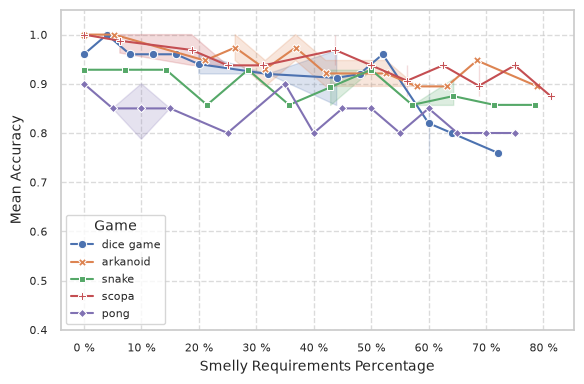

In [14]:
# Define a function to create the plot
def create_plot(data, model_name, file_name):
    # Filter and preprocess data for the given model
    plot_df = data.copy()
    plot_df = plot_df[(plot_df['model'] == model_name)]
    plot_df['game'] = plot_df['game'].replace({'dice_game': 'dice game'})
    plot_df = plot_df.sort_values('percentage_smelly')

    # Set aesthetic style and colors
    sns.set(style="whitegrid")
    palette = {
        'dice game': sns.color_palette()[0],
        'arkanoid': sns.color_palette()[1],
        'snake': sns.color_palette()[2],
        'scopa': sns.color_palette()[3],
        'pong': sns.color_palette()[4]
    }
    hue_order = ['dice game', 'arkanoid', 'snake', 'scopa', 'pong']

    # Create the line plot
    plt.figure(figsize=(6, 4))
    sns.lineplot(x='percentage_smelly', y='accuracy', hue='game', style='game',
                 palette=palette, hue_order=hue_order, style_order=hue_order,
                 data=plot_df, markers=True, dashes=False, linewidth=1.5)

    # Customize x and y axes
    plt.xticks(range(0, 81, 10), ['0 %', '10 %', '20 %', '30 %', '40 %', '50 %', '60 %', '70 %', '80 %'], fontsize=8, rotation=0)
    plt.yticks(fontsize=8)
    plt.ylim(0.4, 1.05)

    # Set labels and title
    plt.xlabel('Smelly Requirements Percentage', fontsize=10)
    plt.ylabel('Mean Accuracy', fontsize=10)

    # Adjust the legend
    plt.legend(title='Game', title_fontsize='10', fontsize='8', loc='lower left')

    # Add grid lines and apply tight layout
    plt.grid(True, linestyle='--', alpha=0.7)
    plt.tight_layout()

    # Save the plot as a PDF and display it
    plt.savefig(file_name, format='pdf', bbox_inches='tight')
    plt.show()

# Use the function for both models
create_plot(accuracy_df, 'gpt-4o-2024-08-06', 'RQ2-BTA.pdf')
# create_plot(accuracy_df, 'llama3.1:70b', 'RQ2-BTA-Llama.pdf')

### Regression analysis

**Fit a Generalized Linear Mixed Model (GLMM) with game and model as random effects**

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.api as sm
import statsmodels.formula.api as smf
from scipy.stats import chi2

# Fit the GLMM with:
# - A random intercept for "game"
# - A random intercept and slope for "model"
glmm = smf.mixedlm(
    "accuracy ~ percentage_smelly",                 # Fixed effects formula
    accuracy_df,                                    # Data
    groups=accuracy_df["game"],                     # Random intercept for game
    re_formula="1 + percentage_smelly",             # Random intercept and slope for model
    vc_formula={"model": "0 + C(model)"}            # Variance components for random intercepts and slopes for model
)

# Fit the model
glmm_fit = glmm.fit()

# Print the summary of the model fit
print(glmm_fit.summary())

# --- Assumption Checks ---
def check_model_assumptions(glmm_fit):
    # --- 1. Check for Normally Distributed Random Effects ---
    random_effects = glmm_fit.random_effects
    random_effects_series = pd.Series([v[0] for v in random_effects.values()])

    # Q-Q plot for random intercepts
    plt.figure()
    sm.qqplot(random_effects_series, line='45')
    plt.title("Q-Q Plot of Random Intercepts (Games)")
    plt.show()

    # --- 2. Linearity Check for Fixed Effects ---
    fitted_values = glmm_fit.fittedvalues
    smelly_percentage = accuracy_df["percentage_smelly"]

    plt.figure()
    plt.scatter(smelly_percentage, fitted_values)
    plt.xlabel("Smelly Percentage")
    plt.ylabel("Fitted Accuracy")
    plt.title("Fitted Values vs Smelly Percentage")
    plt.show()

    # --- 3. Check Normally Distributed Residuals ---
    residuals = glmm_fit.resid

    # Q-Q plot for residuals
    plt.figure()
    sm.qqplot(residuals, line='45')
    plt.title("Q-Q Plot of Residuals")
    plt.show()

    # Histogram of residuals
    plt.figure()
    plt.hist(residuals, bins=30)
    plt.xlabel("Residuals")
    plt.ylabel("Frequency")
    plt.title("Histogram of Residuals")
    plt.show()

    # --- 4. Check for Homoscedasticity (Constant Variance) ---
    plt.figure()
    plt.scatter(fitted_values, residuals)
    plt.axhline(0, color='red', linestyle='--')
    plt.xlabel("Fitted Values")
    plt.ylabel("Residuals")
    plt.title("Residuals vs Fitted Values")
    plt.show()

    # --- 5. Check if the Random Effects Structure is Correct ---
    # Fit a model without the random effects for comparison
    glm_no_random = smf.ols("accuracy ~ percentage_smelly", data=accuracy_df).fit()

    # Compare log-likelihoods (Likelihood Ratio Test)
    llr_test_stat = 2 * (glmm_fit.llf - glm_no_random.llf)
    p_value = chi2.sf(llr_test_stat, df=2)  # 2 df for random intercept and slope for model

    print(f"Likelihood Ratio Test Stat: {llr_test_stat}, p-value: {p_value}")

# Perform assumption checks
check_model_assumptions(glmm_fit)

## LOC Tracing Precision, Recall, and F1

In [15]:
# Define the function to calculate precision, recall, and F1 score
def calculate_precision_recall_f1(row):
    if not isinstance(row['loc_predicted'], list) or not isinstance(row['loc_actual'], list):
        return pd.Series({'precision': np.nan, 'recall': np.nan, 'f1_score': np.nan})

    true_positives = set(row['loc_predicted']).intersection(set(row['loc_actual']))

    # Calculate precision
    if len(row['loc_predicted']) == 0:
        precision = 1.0 if len(row['loc_actual']) == 0 else 0.0
    else:
        precision = len(true_positives) / len(row['loc_predicted'])

    # Calculate recall
    if len(row['loc_actual']) == 0:
        recall = 1.0 if len(row['loc_predicted']) == 0 else 0.0
    else:
        recall = len(true_positives) / len(row['loc_actual'])

    # Calculate F1 score
    if precision + recall == 0:
        f1_score = 0.0
    else:
        f1_score = 2 * (precision * recall) / (precision + recall)

    return pd.Series({'precision': precision, 'recall': recall, 'f1': f1_score})

# Apply the function to compute precision, recall, and F1 score
results_truth_merged_grouped.loc[:, ['precision', 'recall', 'f1']] = results_truth_merged_grouped.apply(calculate_precision_recall_f1, axis=1)

# Group by 'model', 'game', and 'experiment', and calculate the mean precision, recall, and F1 score
precision_recall_per_game_experiment_df = results_truth_merged_grouped.groupby(['model', 'game', 'experiment'])[['precision', 'recall', 'f1', 'percentage_smelly']].mean().reset_index()

# Display the result
precision_recall_per_game_experiment_df

,model,game,experiment,precision,recall,f1,percentage_smelly
0,gpt-4o-2024-08-06,arkanoid,all_smells_01,0.657617,0.802814,0.682318,78.947368
1,gpt-4o-2024-08-06,arkanoid,no_smells_01,0.749369,0.800433,0.731896,0.000000
2,gpt-4o-2024-08-06,arkanoid,random_01,0.625872,0.839610,0.678112,36.842105
3,gpt-4o-2024-08-06,arkanoid,random_02,0.634019,0.797096,0.651244,21.052632
4,gpt-4o-2024-08-06,arkanoid,random_03,0.682350,0.760839,0.678817,68.421053
...,...,...,...,...,...,...,...
105,gpt-4o-2024-08-06,snake,random_16,0.488458,0.623939,0.498954,57.142857
106,gpt-4o-2024-08-06,snake,random_17,0.547524,0.748939,0.576803,42.857143
107,gpt-4o-2024-08-06,snake,random_18,0.550958,0.728105,0.577079,14.285714
108,gpt-4o-2024-08-06,snake,random_19,0.512015,0.623939,0.519814,57.142857


### Line plot of Precision, Recall, and F1

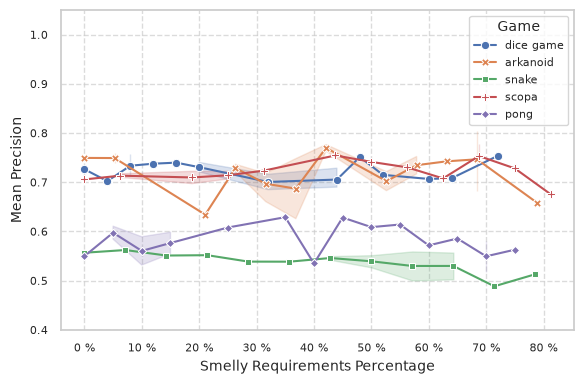

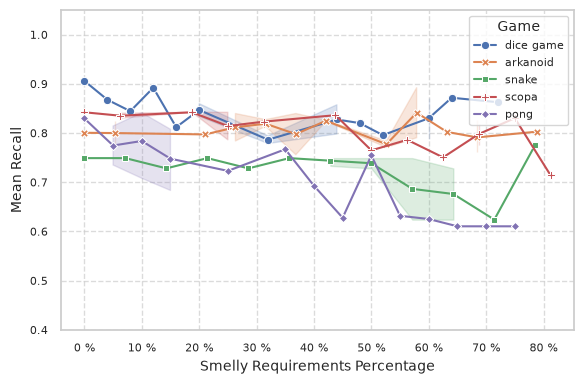

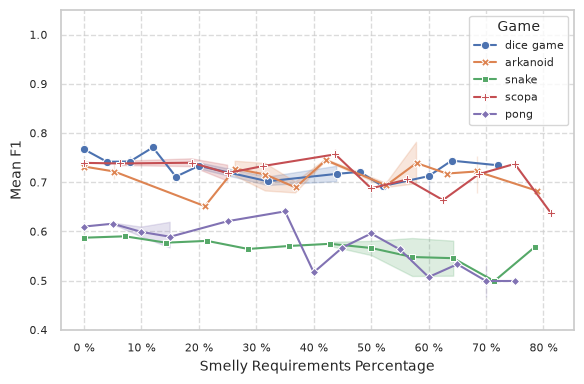

In [32]:
# Define a function to create the plot
def create_plot(data, y_axis, model_name, file_name):
    # Filter and preprocess data for the given model
    plot_df = data.copy()
    plot_df = plot_df[(plot_df['model'] == model_name)]
    plot_df['game'] = plot_df['game'].replace({'dice_game': 'dice game'})
    plot_df = plot_df.sort_values('percentage_smelly')

    # Set aesthetic style and colors
    sns.set(style="whitegrid")
    palette = {
        'dice game': sns.color_palette()[0],
        'arkanoid': sns.color_palette()[1],
        'snake': sns.color_palette()[2],
        'scopa': sns.color_palette()[3],
        'pong': sns.color_palette()[4]
    }
    hue_order = ['dice game', 'arkanoid', 'snake', 'scopa', 'pong']

    # Create the line plot
    plt.figure(figsize=(6, 4))
    sns.lineplot(x='percentage_smelly', y=y_axis, hue='game', style='game',
                 palette=palette, hue_order=hue_order, style_order=hue_order,
                 data=plot_df, markers=True, dashes=False, linewidth=1.5)

    # Customize x and y axes
    plt.xticks(range(0, 81, 10), ['0 %', '10 %', '20 %', '30 %', '40 %', '50 %', '60 %', '70 %', '80 %'], fontsize=8, rotation=0)
    plt.yticks(fontsize=8)
    plt.ylim(0.4, 1.05)

    # Set labels and title
    plt.xlabel('Smelly Requirements Percentage', fontsize=10)
    plt.ylabel(f'Mean {y_axis.capitalize()}', fontsize=10)

    # Adjust the legend
    plt.legend(title='Game', title_fontsize='10', fontsize='8', loc='upper right')

    # Add grid lines and apply tight layout
    plt.grid(True, linestyle='--', alpha=0.7)
    plt.tight_layout()

    # Save the plot as a PDF and display it
    plt.savefig(file_name, format='pdf', bbox_inches='tight')
    plt.show()

# Use the function for both models
create_plot(precision_recall_per_game_experiment_df, 'precision', 'gpt-4o-2024-08-06', 'RQ2-LOC-Precision-GPT.pdf')
create_plot(precision_recall_per_game_experiment_df, 'recall', 'gpt-4o-2024-08-06', 'RQ2-LOC-Recall-GPT.pdf')
create_plot(precision_recall_per_game_experiment_df, 'f1', 'gpt-4o-2024-08-06', 'RQ2-LOC-F1-GPT.pdf')
# create_plot(precision_recall_per_game_experiment_df, 'precision', 'llama3.1:70b', 'RQ2-LOC-Precision-Llama.pdf')
# create_plot(precision_recall_per_game_experiment_df, 'recall', 'llama3.1:70b', 'RQ2-LOC-Recall-Llama.pdf')
# create_plot(precision_recall_per_game_experiment_df, 'f1', 'llama3.1:70b', 'RQ2-LOC-F1-Llama.pdf')


### Regression Analysis

**GLMM for precisions, recall, and f1 with game and model as random effects**

In [ ]:
import pandas as pd
import statsmodels.api as sm
import statsmodels.formula.api as smf
from scipy.stats import chi2

# Assuming you have the precision_recall_per_game_experiment_df loaded with columns:
# 'precision', 'recall', 'f1', 'percentage_smelly', 'game', 'model'

# Initialize an empty dictionary to store model results
model_results = {}

# List of response variables
response_variables = ['precision', 'recall', 'f1']

# Function to fit a GLMM model with random intercept and slope for 'model' and random intercept for 'game'
def fit_glmm(response_var, df):
    print(f"Fitting model for {response_var}...")

    # Fit the GLMM
    glmm = smf.mixedlm(
        f"{response_var} ~ percentage_smelly",        # Fixed effects formula
        df,                                           # Data
        groups=df["game"],                            # Random intercept for game
        re_formula="1 + percentage_smelly",           # Random intercept and slope for model
        vc_formula={"model": "0 + C(model)"}          # Variance components for random intercepts and slopes for model
    )

    # Fit the model
    glmm_fit = glmm.fit()
    return glmm_fit

# Function to create a report for the model
def create_report(model_name, glmm_fit):
    report = f"=============================\n"
    report += f"Summary for model: {model_name}\n"
    report += f"=============================\n"
    report += str(glmm_fit.summary()) + "\n"

    # Likelihood Ratio Test (comparing the GLMM with a simpler OLS model)
    glm_no_random = smf.ols(f"{model_name} ~ percentage_smelly", data=precision_recall_per_game_experiment_df).fit()
    llr_test_stat = 2 * (glmm_fit.llf - glm_no_random.llf)
    p_value = chi2.sf(llr_test_stat, df=2)  # 2 degrees of freedom for random intercept and slope

    report += f"--- Likelihood Ratio Test ---\n"
    report += f"LR Test Stat: {llr_test_stat}\n"
    report += f"p-value: {p_value}\n\n"

    return report

# Fit models for 'precision', 'recall', and 'f1' and store results
for response_var in response_variables:
    glmm_fit = fit_glmm(response_var, precision_recall_per_game_experiment_df)
    model_results[response_var] = glmm_fit

# Generate a comprehensive report
full_report = ""
for response_var, glmm_fit in model_results.items():
    full_report += create_report(response_var, glmm_fit)

# Output the comprehensive report
print(full_report)

# Optionally, you can save the report to a text file
with open("glmm_report_precision_recall_f1.txt", "w") as report_file:
    report_file.write(full_report)

# RQ3: Tracing Performance for Smell Categories

Binary tracing accuracy (BTA) and the LOC tracing precision and recall achieved for smelly requirements of the three categories.  

### Accuracy (BTA) for each category

In [25]:
accuracy_results = []

for model in results_truth_merged_grouped['model'].unique():
  for category in results_truth_merged_grouped['smell_category'].unique():
        category_df = results_truth_merged_grouped[(results_truth_merged_grouped['smell_category'] == category) &
                                                   (results_truth_merged_grouped['model'] == model)]
        if not category_df.empty:
          # Calculate the correct predictions based on the 'smelly' condition
          correct_predictions = category_df.apply(lambda row: row['implemented_pred'] == (row['smelly_traceable'] if row['smelly'] else row['implemented_actual']),axis=1)
          accuracy = correct_predictions.mean()
          accuracy_results.append({
              'model': model,
              'smell_category': category,
              'accuracy': accuracy
          })

accuracy_category = pd.DataFrame(accuracy_results)
accuracy_category

,model,smell_category,accuracy
0,gpt-4o-2024-08-06,semantic,0.829545
1,gpt-4o-2024-08-06,syntactic,0.977273
2,gpt-4o-2024-08-06,lexical,0.890152


## LOC Precisions and Recall for each category

In [26]:
# Group by 'smell category' and calculate the mean precision and recall
precision_recall_per_category = results_truth_merged_grouped.groupby(['model', 'smell_category'])[['precision', 'recall', 'f1']].mean().reset_index()

precision_recall_per_category

,model,smell_category,precision,recall,f1
0,gpt-4o-2024-08-06,lexical,0.689842,0.760691,0.687415
1,gpt-4o-2024-08-06,semantic,0.649157,0.784442,0.654740
2,gpt-4o-2024-08-06,syntactic,0.734056,0.856913,0.737566


## Export to Latex

In [27]:
# prompt: Using accuracy_category, precision_recall_per_category: Create Latex code that presents the values of accuracy_category, precision_recall_per_category_df as a Latex table. Make sure that numbers are cut after the second digit. The order of the categories shall be 1. lexical, 2. syntactic, 3. semantic. Create only the code for the body of the table.

# Create the LaTeX table body
table_body = ""
for category in ["lexical", "syntactic", "semantic"]:
  accuracy_gpt = f"{accuracy_category[(accuracy_category['smell_category'] == category) & (accuracy_category['model'] == 'gpt-4o-2024-08-06')]['accuracy'].values[0]:.2f}"
  precision_gpt = f"{precision_recall_per_category[(precision_recall_per_category['smell_category'] == category) & (precision_recall_per_category['model'] == 'gpt-4o-2024-08-06')]['precision'].values[0]:.2f}"
  recall_gpt = f"{precision_recall_per_category[(precision_recall_per_category['smell_category'] == category) & (precision_recall_per_category['model'] == 'gpt-4o-2024-08-06')]['recall'].values[0]:.2f}"
  f1_gpt = f"{precision_recall_per_category[(precision_recall_per_category['smell_category'] == category) & (precision_recall_per_category['model'] == 'gpt-4o-2024-08-06')]['f1'].values[0]:.2f}"
  # accuracy_llama = f"{accuracy_category[(accuracy_category['smell_category'] == category) & (accuracy_category['model'] == 'llama3.1:70b')]['accuracy'].values[0]:.2f}"
  # precision_llama = f"{precision_recall_per_category[(precision_recall_per_category['smell_category'] == category) & (precision_recall_per_category['model'] == 'llama3.1:70b')]['precision'].values[0]:.2f}"
  # recall_llama = f"{precision_recall_per_category[(precision_recall_per_category['smell_category'] == category) & (precision_recall_per_category['model'] == 'llama3.1:70b')]['recall'].values[0]:.2f}"
  # f1_llama = f"{precision_recall_per_category[(precision_recall_per_category['smell_category'] == category) & (precision_recall_per_category['model'] == 'llama3.1:70b')]['f1'].values[0]:.2f}"
  # table_body += f"{category} & {accuracy_gpt} & {precision_gpt} & {recall_gpt}& {f1_gpt} & {accuracy_llama} & {precision_llama} & {recall_llama} & {f1_gpt}\\\\\n"
  table_body += f"{category} & {accuracy_gpt} & {precision_gpt} & {recall_gpt}& {f1_gpt} & {f1_gpt}\\\\\n"

print(table_body)


lexical & 0.89 & 0.69 & 0.76& 0.69 & 0.69\\
syntactic & 0.98 & 0.73 & 0.86& 0.74 & 0.74\\
semantic & 0.83 & 0.65 & 0.78& 0.65 & 0.65\\



# Descriptive Statistics

Distribution of smell types and categories

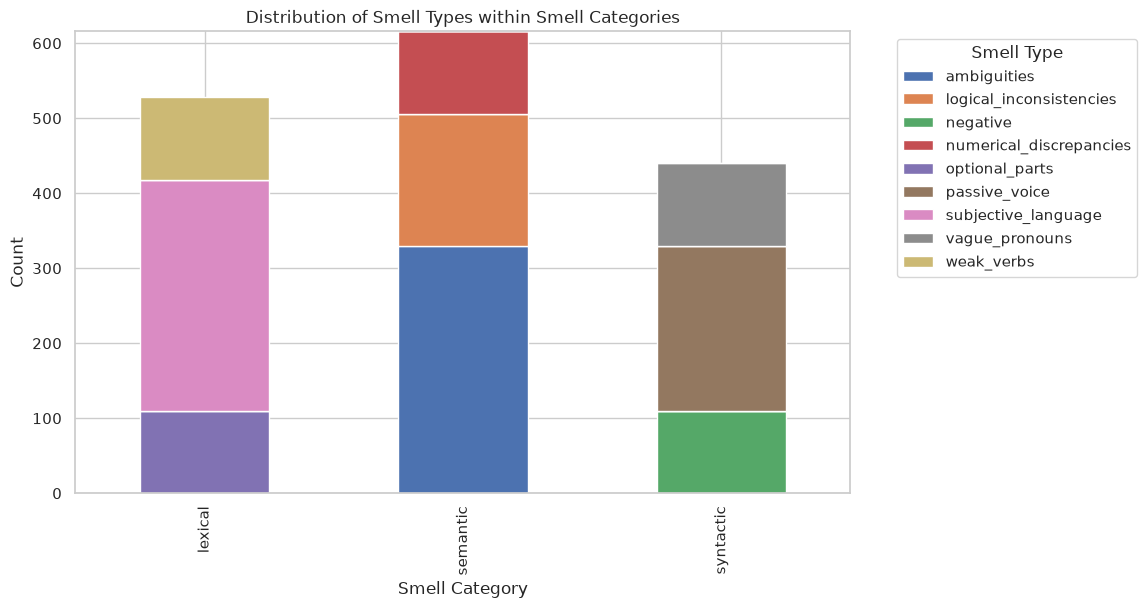

In [28]:
# prompt: Plot a stacked bar chart that shows the distribution of smell_types within smell_category in results_truth_merged_smelly. Plot the legend outside of the plot.

# Calculate the counts for each combination of smell_category and smell_type
counts = results_truth_merged_grouped.groupby(['smell_category', 'smell_type']).size().unstack()

# Create the stacked bar chart
ax = counts.plot(kind='bar', stacked=True, figsize=(10, 6))

# Set labels and title
ax.set_xlabel("Smell Category")
ax.set_ylabel("Count")
ax.set_title("Distribution of Smell Types within Smell Categories")

# Move the legend outside of the plot
plt.legend(title="Smell Type", bbox_to_anchor=(1.05, 1), loc='upper left')

# Display the plot
plt.show()


**Distributions of single Variables**

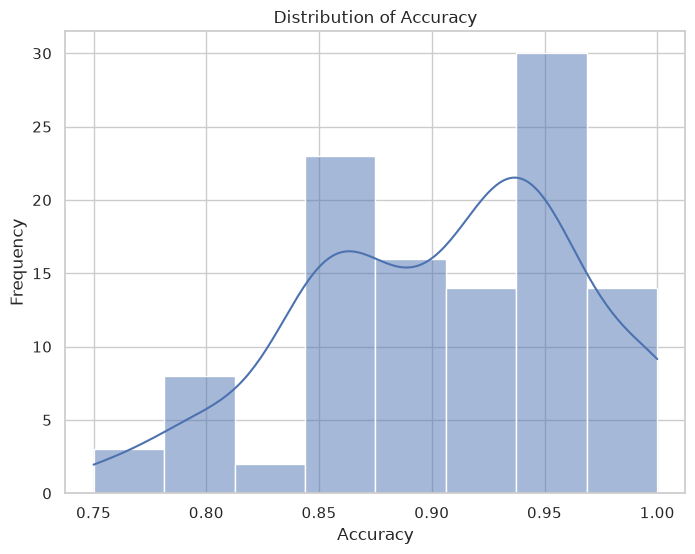

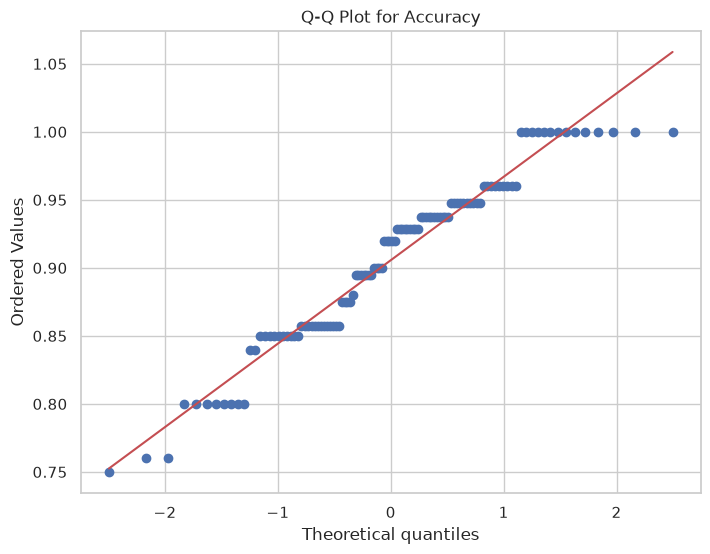

Shapiro-Wilk Test for Normality of Accuracy: W=0.9504, p-value=0.0004


In [29]:
# prompt: Plot the distribution of the accuracy column in accuracy_df and check it for normality.

import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# Plot the distribution of the accuracy column
plt.figure(figsize=(8, 6))
sns.histplot(accuracy_df['accuracy'], kde=True)
plt.title('Distribution of Accuracy')
plt.xlabel('Accuracy')
plt.ylabel('Frequency')
plt.show()

# Check for normality using a Q-Q plot
plt.figure(figsize=(8, 6))
stats.probplot(accuracy_df['accuracy'], dist="norm", plot=plt)
plt.title('Q-Q Plot for Accuracy')
plt.show()

# Perform the Shapiro-Wilk test for normality
shapiro_test = stats.shapiro(accuracy_df['accuracy'])
print(f'Shapiro-Wilk Test for Normality of Accuracy: W={shapiro_test.statistic:.4f}, p-value={shapiro_test.pvalue:.4f}')


In [30]:
import pandas as pd
import statsmodels.api as sm
from statsmodels.formula.api import glm
from statsmodels.genmod.families import Gaussian, Binomial, Poisson, Gamma, InverseGaussian

def fit_glm_and_compare(data, formula, dependent_variable):
    # Fit models with different families
    families = {
        'Gaussian': Gaussian(),
        'Binomial': Binomial(),
        'Poisson': Poisson(),
        'Gamma': Gamma(),
        'Inverse Gaussian': InverseGaussian()
    }

    # Store results
    model_results = {}

    # Fit a model for each family
    for family_name, family in families.items():
        try:
            model = glm(formula=formula, data=data, family=family)
            result = model.fit()
            # Store the AIC value and the model
            model_results[family_name] = {'AIC': result.aic, 'model': result}
        except Exception as e:
            print(f"Could not fit {family_name} model: {e}")

    # Print AIC values
    print("AIC values for each family:")
    for family_name, result in model_results.items():
        print(f"{family_name}: AIC = {result['AIC']}")

    # Find the family with the lowest AIC
    best_fit = min(model_results, key=lambda k: model_results[k]['AIC'])

    print(f"\nBest fitting model is {best_fit} with AIC = {model_results[best_fit]['AIC']}")

    # Return the best fitting model
    return model_results[best_fit]['model']

# Fit and compare the models
best_model = fit_glm_and_compare(accuracy_df, 'accuracy ~ percentage_smelly', 'accuracy')
best_model = fit_glm_and_compare(precision_recall_per_game_experiment_df, 'precision ~ percentage_smelly', 'precision')
best_model = fit_glm_and_compare(precision_recall_per_game_experiment_df, 'recall ~ percentage_smelly', 'recall')
best_model = fit_glm_and_compare(precision_recall_per_game_experiment_df, 'f1 ~ percentage_smelly', 'f1')

AIC values for each family:
Gaussian: AIC = -317.7341959163953
Binomial: AIC = 54.2221641964414
Poisson: AIC = 215.0636894823964
Gamma: AIC = -315.30966925158964
Inverse Gaussian: AIC = -313.7821951368315

Best fitting model is Gaussian with AIC = -317.7341959163953
AIC values for each family:
Gaussian: AIC = -221.7341765131525
Binomial: AIC = 99.04925979968067
Poisson: AIC = 186.90990127257268
Gamma: AIC = -218.00385247414573
Inverse Gaussian: AIC = -215.66105706674114

Best fitting model is Gaussian with AIC = -221.7341765131525
AIC values for each family:
Gaussian: AIC = -279.2524838057261
Binomial: AIC = 84.09706480120032
Poisson: AIC = 201.43043405242432
Gamma: AIC = -271.5840529282558
Inverse Gaussian: AIC = -267.07615030600607

Best fitting model is Gaussian with AIC = -279.2524838057261
AIC values for each family:
Gaussian: AIC = -239.4330618994271
Binomial: AIC = 98.41983870776502
Poisson: AIC = 187.2847255212028
Gamma: AIC = -234.2153858638742
Inverse Gaussian: AIC = -230.987

/home/jillian/projects/27153441/.venv/lib/python3.12/site-packages/statsmodels/base/model.py:243: DomainWarning: The InversePower link function does not respect the domain of the Gamma family.
  mod = cls(endog, exog, *args, **kwargs)
/home/jillian/projects/27153441/.venv/lib/python3.12/site-packages/statsmodels/base/model.py:243: DomainWarning: The InversePower link function does not respect the domain of the Gamma family.
  mod = cls(endog, exog, *args, **kwargs)
/home/jillian/projects/27153441/.venv/lib/python3.12/site-packages/statsmodels/base/model.py:243: DomainWarning: The InversePower link function does not respect the domain of the Gamma family.
  mod = cls(endog, exog, *args, **kwargs)
/home/jillian/projects/27153441/.venv/lib/python3.12/site-packages/statsmodels/base/model.py:243: DomainWarning: The InversePower link function does not respect the domain of the Gamma family.
  mod = cls(endog, exog, *args, **kwargs)


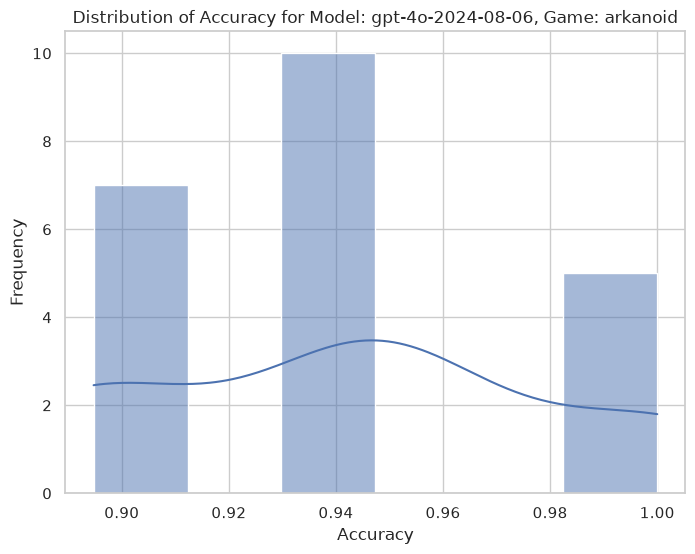

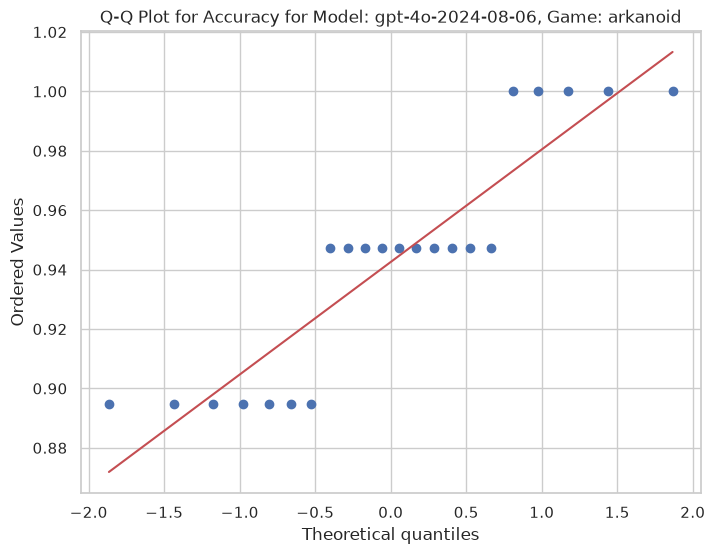

Model: gpt-4o-2024-08-06, Game: arkanoid
Shapiro-Wilk Test for Normality of Accuracy: W=0.8127, p-value=0.0008
--------------------------------------------------


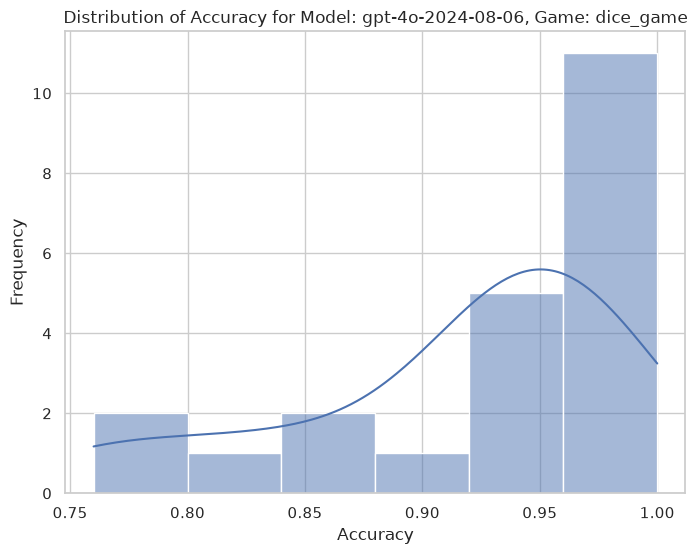

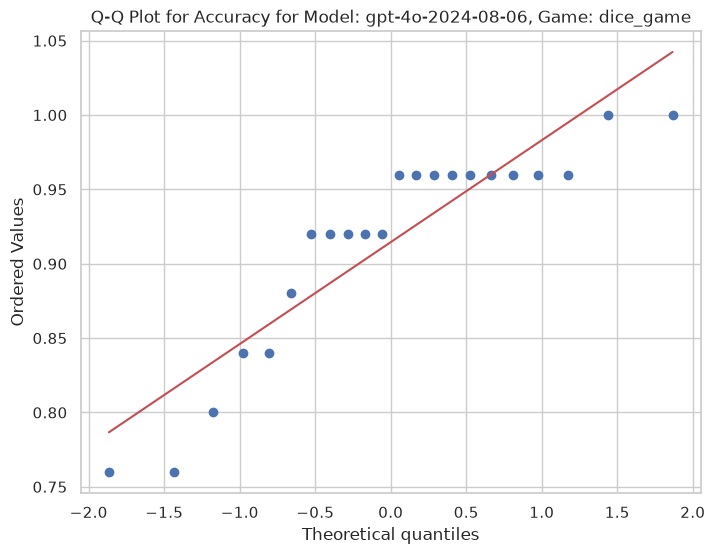

Model: gpt-4o-2024-08-06, Game: dice_game
Shapiro-Wilk Test for Normality of Accuracy: W=0.8331, p-value=0.0017
--------------------------------------------------


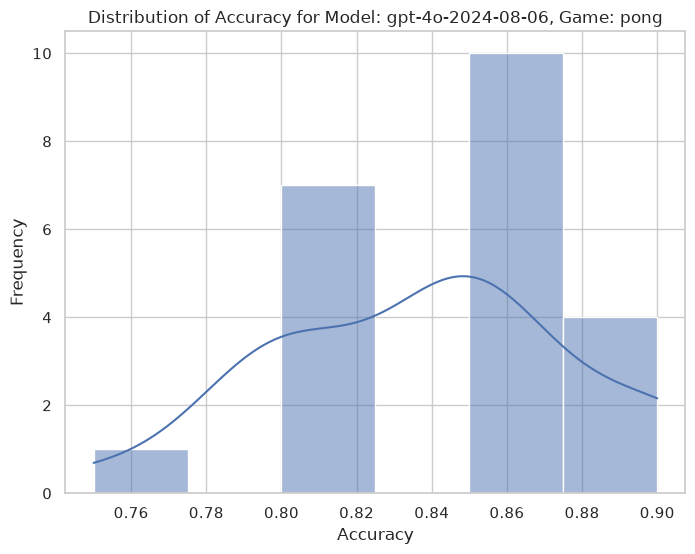

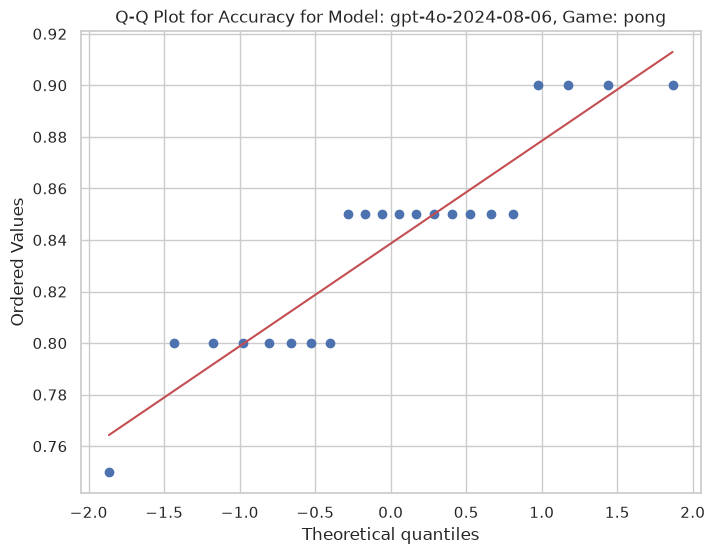

Model: gpt-4o-2024-08-06, Game: pong
Shapiro-Wilk Test for Normality of Accuracy: W=0.8689, p-value=0.0075
--------------------------------------------------


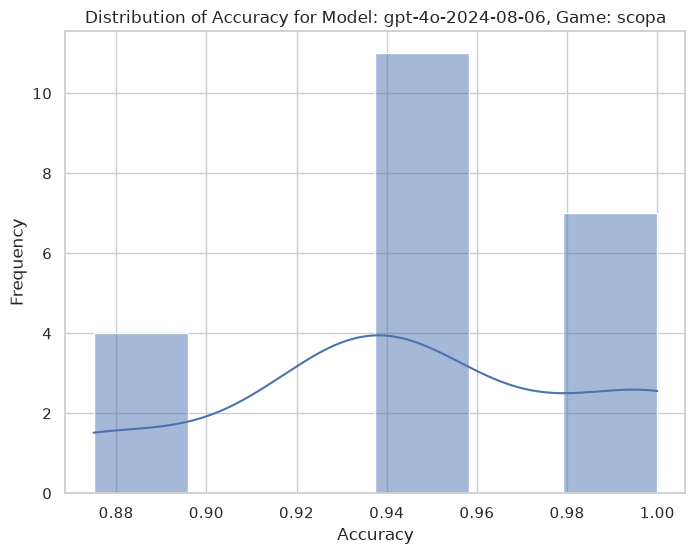

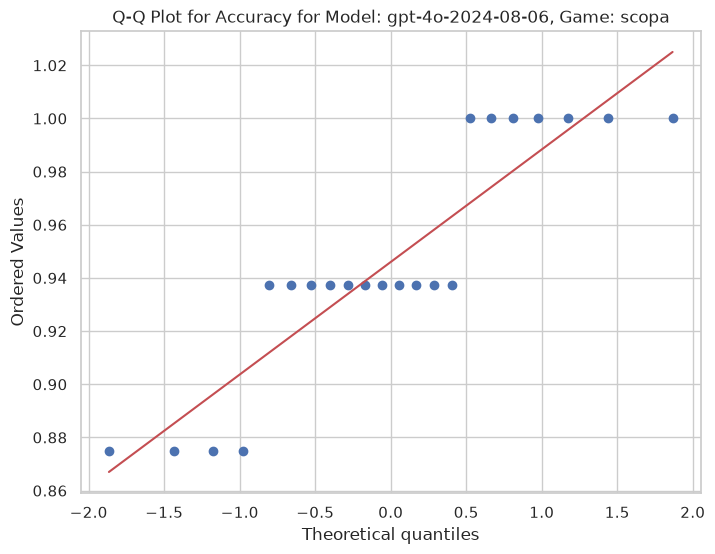

Model: gpt-4o-2024-08-06, Game: scopa
Shapiro-Wilk Test for Normality of Accuracy: W=0.8071, p-value=0.0006
--------------------------------------------------


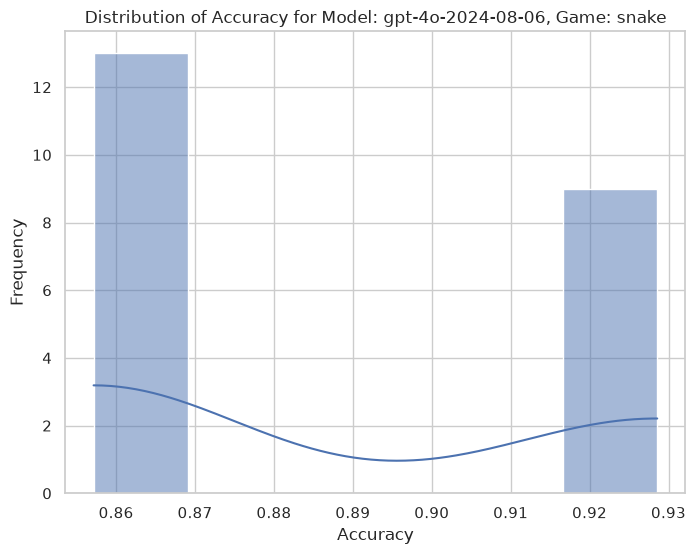

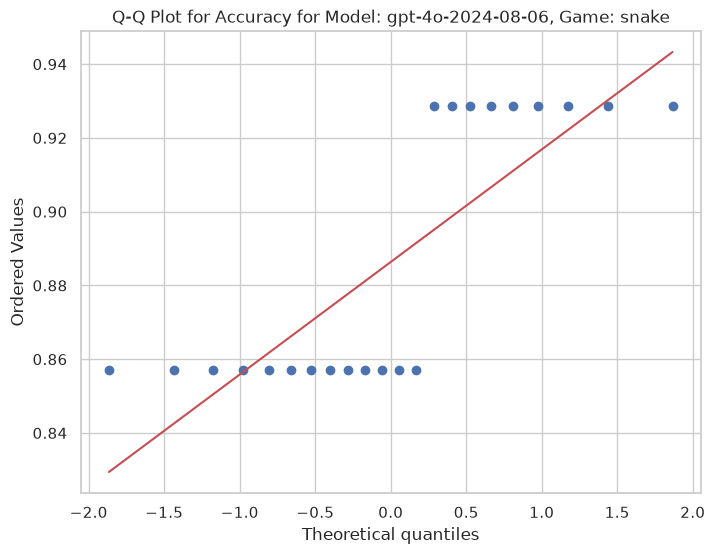

Model: gpt-4o-2024-08-06, Game: snake
Shapiro-Wilk Test for Normality of Accuracy: W=0.6281, p-value=0.0000
--------------------------------------------------


In [31]:
# prompt: Plot the distribution of the accuracy values in accuracy_df per game and model. Check the distributions for normality.

import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

for model in accuracy_df['model'].unique():
  for game in accuracy_df['game'].unique():
    df_subset = accuracy_df[(accuracy_df['model'] == model) & (accuracy_df['game'] == game)]
    if not df_subset.empty:
      # Plot the distribution of accuracy
      plt.figure(figsize=(8, 6))
      sns.histplot(df_subset['accuracy'], kde=True)
      plt.title(f'Distribution of Accuracy for Model: {model}, Game: {game}')
      plt.xlabel('Accuracy')
      plt.ylabel('Frequency')
      plt.show()

      # Check for normality using a Q-Q plot
      plt.figure(figsize=(8, 6))
      stats.probplot(df_subset['accuracy'], dist="norm", plot=plt)
      plt.title(f'Q-Q Plot for Accuracy for Model: {model}, Game: {game}')
      plt.show()

      # Perform the Shapiro-Wilk test for normality
      shapiro_test = stats.shapiro(df_subset['accuracy'])
      print(f'Model: {model}, Game: {game}')
      print(f'Shapiro-Wilk Test for Normality of Accuracy: W={shapiro_test.statistic:.4f}, p-value={shapiro_test.pvalue:.4f}')
      print('-' * 50)
